# Craterellus CNN runs overview

Binary image classification from scratch: **"Is there a *suppilovahvero* (Craterellus tubaeformis) in this photo?"**

- **Dataset:** shared 70 / 15 / 15 split from `dataset/split.csv` (`train`: 249 + 34, `val`: 50 + 7, `test`: 50 + 7)
- **Labels:** `Target_Absent = 0`, `Target_Present = 1`
- **Core architecture:** 4 × (`Conv2D` + `MaxPooling2D`) with 32–64–128–128 filters, `3×3` ReLU, `binary_crossentropy`, `Adam`, `SEED = 0`
- **Rule:** all tuning decisions are made on **validation**; the held-out **test** set is evaluated once at the end.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path("results/cnn") if Path("results/cnn").exists() else Path("../../results/cnn")

table = pd.read_csv(ROOT / "tuning_table.csv")
table

,run,what_changed,train_acc,val_acc,gap,val_precision,val_recall,val_f1,epochs,learnings
0,run1_baseline,whole photos 224. plain baseline,1.0,0.912,0.088,0.909,1.0,0.952,30,"Overfits (train 1.000 vs val 0.912, val_loss 0..."


=== run1_baseline ===
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────

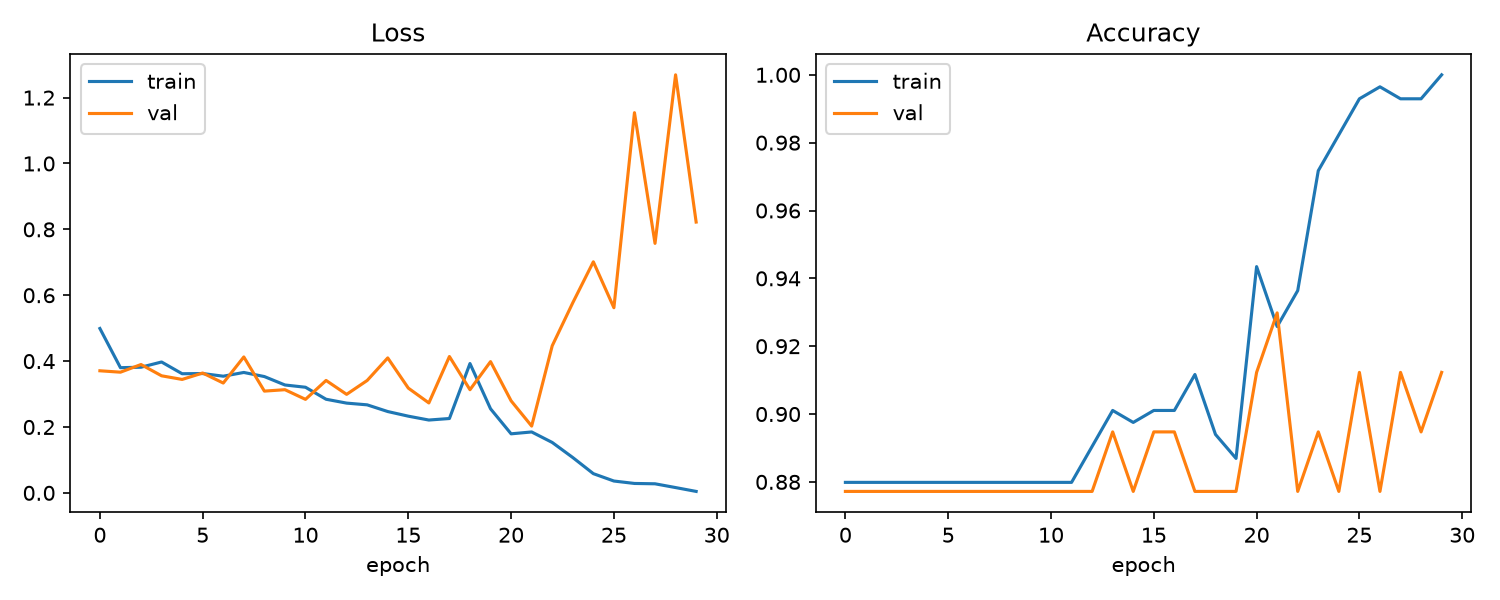

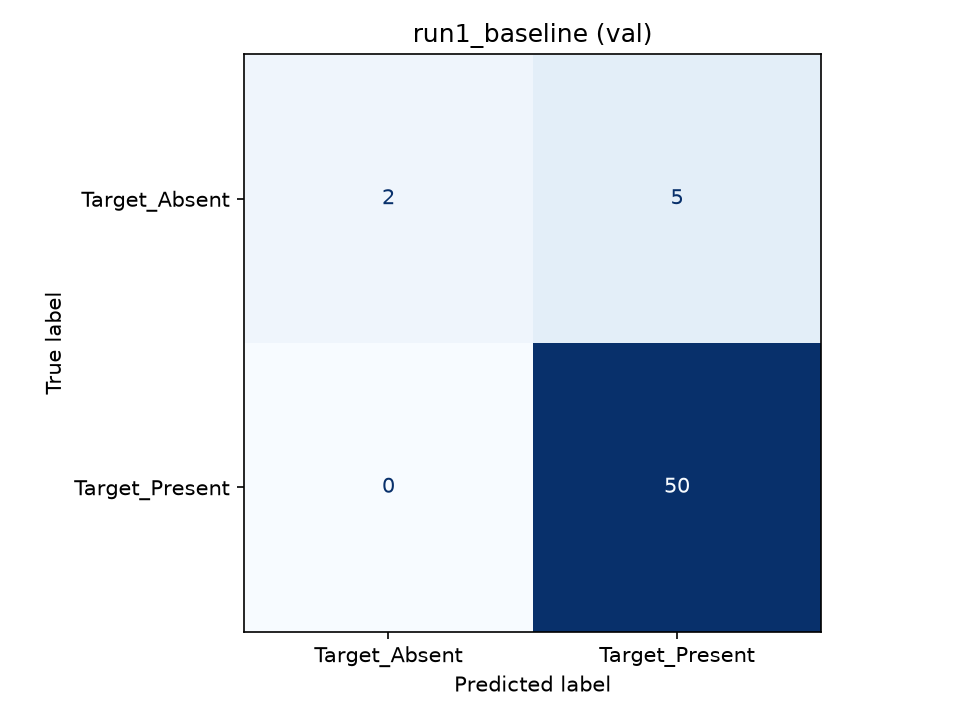

In [2]:
for run in table["run"]:
    print("===", run, "===")
    summary = ROOT / run / "summary.txt"
    if summary.exists():
        print(summary.read_text())
    for name in ["curves.png", "confusion_matrix.png"]:
        img = ROOT / run / name
        if img.exists():
            display(Image(filename=str(img), width=550))